## 🔹 Paso 1: Cargar y validar la calidad de los datos

---

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:** Familiarizarse con la estructura de los datasets del negocio antes de analizarlos.

In [ ]:
# importar librerías

import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from scipy.stats import levene
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import pointbiserialr

In [ ]:
# cargar archivos
orders = pd.read_csv ('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_orders_raw.csv')
catalog = pd.read_csv ('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_catalog.csv')
marketing = pd.read_csv ('https://practicum-content.s3.amazonaws.com/datasets/rappiplus_marketing_spend.csv')


In [ ]:
# explorar datasets
# tu código aquí
print("------------------------------------------------------------")
print("Cantidad de datos unicos")
print("------------------------------------------------------------")
print(orders['id_pedido'].nunique())
print("\n------------------------------------------------------------")
print("Informacion del dataset")
print("------------------------------------------------------------")
orders.info()
print("\n------------------------------------------------------------")
print("Nulos por columnas")
print("------------------------------------------------------------")
print(orders.isna().sum())
print("\n------------------------------------------------------------")
print("Porcentaje de nulos por columnas")
print("------------------------------------------------------------")
print(orders.isna().mean())
print("\n------------------------------------------------------------")
print("Número de nulos totales")
print("------------------------------------------------------------")
print(orders.isna().sum().sum())

------------------------------------------------------------
Cantidad de datos unicos
------------------------------------------------------------
25000

------------------------------------------------------------
Informacion del dataset
------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_pedido           25100 non-null  object 
 1   id_usuario          25100 non-null  object 
 2   fecha_hora_pedido   25100 non-null  object 
 3   pais                24800 non-null  object 
 4   dispositivo         25080 non-null  object 
 5   fuente_referencia   25070 non-null  object 
 6   nombre_producto     25070 non-null  object 
 7   categoria_producto  25020 non-null  object 
 8   cantidad            25050 non-null  float64
 9   precio_unitario     25050 non-null  float64
 10

**Observaciones**
- De 25,000 pedidos hay 25100, posibles duplicados o nulos.
- Aqui se ve que `fecha_hora_pedido`se encuentra como tipo $object$ por lo que hay que cambiarla a $date$.
- `pais`contiene 300 nulos que corresponde al $1.19\%$.
- `dispositivo` contiene 20 nulos que corresponde al $0.079\%$.
- `fuente_referencia` contiene 30 nulos que corresponde al $0.12\%$.
- `nombre_producto`contiene 30 nulos que corresponde al $0.12\%$.
- `categoria_producto` contiene 80 nulos que corresponde al $0.032\%$.
- `cantidad` contiene  50 nulos que corresponde al $0.2\%$.
- `precio_unitario` contiene  50 nulos que corresponde al $0.2\%$.
- `monto_descuento` contiene 50 nulos que corresponde al $0.2\%$.


In [ ]:
print("------------------------------------------------------------")
print("Cantidad de datos unicos")
print("------------------------------------------------------------")
print(orders['nombre_producto'].nunique())
print("\n------------------------------------------------------------")
print("Informacion del dataset")
print("------------------------------------------------------------")
catalog.info()
print("\n------------------------------------------------------------")
print("Nulos por columnas")
print("------------------------------------------------------------")
print(catalog.isna().sum())
print("\n------------------------------------------------------------")
print("Porcentaje de nulos por columnas")
print("------------------------------------------------------------")
print(catalog.isna().mean())
print("\n------------------------------------------------------------")
print("Número de nulos totales")
print("------------------------------------------------------------")
print(catalog.isna().sum().sum())


------------------------------------------------------------
Cantidad de datos unicos
------------------------------------------------------------
7

------------------------------------------------------------
Informacion del dataset
------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   nombre_producto     7 non-null      object 
 1   categoria_producto  7 non-null      object 
 2   costo_unitario      7 non-null      float64
 3   proveedor           7 non-null      object 
dtypes: float64(1), object(3)
memory usage: 352.0+ bytes

------------------------------------------------------------
Nulos por columnas
------------------------------------------------------------
nombre_producto       0
categoria_producto    0
costo_unitario        0
proveedor             0
dtype: int64

-

**Observaciones**
- En este dataset, todas las columnas tienen su tipo de dato correcto.
- No existen nulos.

In [ ]:
print("------------------------------------------------------------")
print("Cantidad de datos unicos")
print("------------------------------------------------------------")
print(marketing['id_campaña'].nunique())
print("\n------------------------------------------------------------")
print("información del Dataset")
print("------------------------------------------------------------")
marketing.info()
print("\n------------------------------------------------------------")
print("Nulos por columna")
print("------------------------------------------------------------")
print(marketing.isna().sum())
print("\n------------------------------------------------------------")
print("Porcenta de nulos por columna")
print("------------------------------------------------------------")
print(marketing.isna().mean())
print("\n------------------------------------------------------------")
print("Número de nulos totales")
print("------------------------------------------------------------")
print(marketing.isna().sum().sum())


------------------------------------------------------------
Cantidad de datos unicos
------------------------------------------------------------
9

------------------------------------------------------------
información del Dataset
------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   fecha       1620 non-null   object 
 1   pais        1620 non-null   object 
 2   id_campaña  1620 non-null   object 
 3   canal       1519 non-null   object 
 4   gasto       1620 non-null   float64
dtypes: float64(1), object(4)
memory usage: 63.4+ KB

------------------------------------------------------------
Nulos por columna
------------------------------------------------------------
fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

-------------

**Observaciones**
- `fecha`se encuentra como tipo $object$ por lo que hay que cambiarla a $date$.
- `canal` contiene 101 nulos que corresponde al $6.23\%$.

---

### Revisión y calidad de datos

**🎯 Objetivo:** Detectar y corregir problemas en los datos que puedan afectar el análisis de revenue, costos y rentabilidad.

Se revisan los 3 datasets
- Validar y convertir fechas al formato correcto (check)
- Revisar variables numéricas (sin negativos o ceros inválidos)   (check)
- Verificar consistencia de montos  (check)
- Eliminar duplicados  (check)
- Revisar variables categóricas

---

**VALIDAR Y CONVERTIR FECHAS**

In [ ]:
# Validar y convertir fechas al formato correcto

orders['fecha_hora_pedido'] = pd.to_datetime(orders["fecha_hora_pedido"], errors = "coerce")
orders.info()

marketing['fecha'] = pd.to_datetime(marketing['fecha'], errors= "coerce")
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                24800 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25020 non-null  object        
 8   cantidad            25050 non-null  float64       
 9   precio_unitario     25050 non-null  float64       
 10  monto_descuento     25050 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB
<class 'pandas.core.frame.DataFrame'

- **REVISAR VARIABLES NUMERICAS**
- **VERIFICAR CONSISTENCIA DE MONTOS**

In [ ]:
#Revisar variables numericas (sin negativos o ceros invalidos)

col_numericas_orders = orders[['cantidad', 'precio_unitario', 'monto_descuento', 'monto_total']]
col_numericas_catalog = catalog[['costo_unitario']]
col_numericas_marketing = marketing[['gasto']]

print("ORDERS")
print(col_numericas_orders.describe())
print("\nCATALOG")
print(col_numericas_catalog.describe())
print("\nMARKETING")
print(col_numericas_marketing.describe())


ORDERS
           cantidad  precio_unitario  monto_descuento   monto_total
count  25050.000000     25050.000000     25050.000000  2.510000e+04
mean       7.092735       259.305549         4.500798  2.072680e+03
std      296.277003       138.726461         5.223010  9.894995e+04
min       -2.000000        20.030000         0.000000 -4.926500e+02
25%        1.000000       138.377500         0.000000  1.805075e+02
50%        2.000000       258.715000         0.000000  3.417500e+02
75%        2.000000       380.332500        10.000000  5.185800e+02
max    20000.000000       499.960000        15.000000  8.840200e+06

CATALOG
       costo_unitario
count        7.000000
mean       102.252857
std        111.011563
min         10.120000
25%         16.905000
50%         25.210000
75%        182.975000
max        280.680000

MARKETING
            gasto
count  1620.00000
mean   1772.74292
std     734.43294
min     501.11000
25%    1128.03000
50%    1782.42500
75%    2420.68500
max    2999.36000


**Observaciones**
-- ORDERS --
- `cantidad` contiene un valor $mínino$ de -2, eso es un valor imposible.
- `monto_total` contiene un valor $mínimo$ de -$492.65, eso es un valor imposible.

-- CATALOG --
- Aqui todo bien.

-- MARKETING --
- Aqui todo bien.


In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25100 entries, 0 to 25099
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25100 non-null  object        
 1   id_usuario          25100 non-null  object        
 2   fecha_hora_pedido   25100 non-null  datetime64[ns]
 3   pais                24800 non-null  object        
 4   dispositivo         25080 non-null  object        
 5   fuente_referencia   25070 non-null  object        
 6   nombre_producto     25070 non-null  object        
 7   categoria_producto  25020 non-null  object        
 8   cantidad            25050 non-null  float64       
 9   precio_unitario     25050 non-null  float64       
 10  monto_descuento     25050 non-null  float64       
 11  monto_total         25100 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


In [ ]:
#Sustituimos los sentinels en 'cantidad' por la mediana
cantidad_mediana = orders["cantidad"].median()
orders['cantidad'] = np.where(orders["cantidad"]==-2, cantidad_mediana, orders["cantidad"])

In [ ]:
#Al revisar 'cantidad' se observó que también hay valores de -1
cantidad_mediana = orders["cantidad"].median()
orders['cantidad'] = np.where(orders["cantidad"]==-1, cantidad_mediana, orders["cantidad"])

In [ ]:
#Sustituimos los sentinels en 'monto_total' por la mediana (muchos valores negativos)
monto_total_mediana = orders['monto_total'].median()
orders['monto_total'] = np.where(orders['monto_total']< 0, monto_total_mediana, orders['monto_total'])

In [ ]:
#Fechas imposibles
orders['fecha_hora_pedido'].describe()

count                   25100
unique                    181
top       2025-06-25 00:00:00
freq                      176
first     2025-01-01 00:00:00
last      2025-06-30 00:00:00
Name: fecha_hora_pedido, dtype: object

**ELIMINAR DUPLICADOS**
- $ORDERS$

In [ ]:
print('Orders = ', orders.duplicated().sum())
print('Catalog = ', catalog.duplicated().sum())
print('Marketing = ', marketing.duplicated().sum())

Orders =  100
Catalog =  0
Marketing =  0


In [ ]:
orders = orders.drop_duplicates(subset= 'id_pedido', keep= "first").reset_index(drop=True)
orders.duplicated().sum()

0

In [ ]:
orders.isna().sum()/25000

id_pedido             0.0000
id_usuario            0.0000
fecha_hora_pedido     0.0000
pais                  0.0120
dispositivo           0.0008
fuente_referencia     0.0012
nombre_producto       0.0012
categoria_producto    0.0032
cantidad              0.0020
precio_unitario       0.0020
monto_descuento       0.0020
monto_total           0.0000
dtype: float64

**ELIMINAR/SUSTITUIR NULOS**
- $VARIABLES$ $CATEGORICAS$

In [ ]:
orders.isnull().any()

id_pedido             False
id_usuario            False
fecha_hora_pedido     False
pais                   True
dispositivo            True
fuente_referencia      True
nombre_producto        True
categoria_producto     True
cantidad               True
precio_unitario        True
monto_descuento        True
monto_total           False
dtype: bool

In [ ]:
#Columnas de ORDERS con filas nulas.
orders_col_con_nulos= orders.columns[orders.isnull().any()]
#Filas con nulos, mostrando id_pedido + solo las columnas con nulos
orders.loc[orders[orders_col_con_nulos].isnull().any(axis=1), ['id_pedido'] + list(orders_col_con_nulos)]

,id_pedido,pais,dispositivo,fuente_referencia,nombre_producto,categoria_producto,cantidad,precio_unitario,monto_descuento
24,order_24,Colombia,NaN,organic,Sneakers-Urban-42,Moda,2.0,117.99,0.0
25,order_25,Argentina,NaN,social,Vacuum-Pro-Black,Hogar,1.0,183.50,5.0
26,order_26,Colombia,NaN,organic,Blender-XL-Red,Hogar,1.0,331.52,15.0
27,order_27,colombia,NaN,paid_search,Phone-Pro-128GB,Electronica,2.0,449.48,5.0
28,order_28,Mexico,NaN,social,Phone-Pro-128GB,Electronica,1.0,60.70,10.0
...,...,...,...,...,...,...,...,...,...
419,order_419,NaN,mobile,social,Jacket-Winter-M,Moda,1.0,172.07,0.0
420,order_420,NaN,desktop,organic,Phone-Pro-128GB,Electronica,2.0,369.70,0.0
421,order_421,NaN,mobile,organic,Jacket-Winter-M,Moda,2.0,209.25,0.0
422,order_422,NaN,mobile,organic,Sneakers-Urban-42,Moda,2.0,350.87,10.0


----------
- $País$
----------

In [ ]:
orders.info()
orders_col_categoricas= [['pais', 'dispositivo', 'fuente_referencia', 'nombre_producto',
                          'categoria_producto']]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_pedido           25000 non-null  object        
 1   id_usuario          25000 non-null  object        
 2   fecha_hora_pedido   25000 non-null  datetime64[ns]
 3   pais                24700 non-null  object        
 4   dispositivo         24980 non-null  object        
 5   fuente_referencia   24970 non-null  object        
 6   nombre_producto     24970 non-null  object        
 7   categoria_producto  24920 non-null  object        
 8   cantidad            24950 non-null  float64       
 9   precio_unitario     24950 non-null  float64       
 10  monto_descuento     24950 non-null  float64       
 11  monto_total         25000 non-null  float64       
dtypes: datetime64[ns](1), float64(4), object(7)
memory usage: 2.3+ MB


In [ ]:
#Remover espacio en blanco de los lados
orders['pais'] = orders['pais'].str.strip()

In [ ]:
orders['pais'].nunique()

6

In [ ]:
orders['pais'].value_counts()

Colombia     7481
Mexico       7478
Argentina    7259
mexico        863
colombia      823
argentina     796
Name: pais, dtype: int64

**Obervaciones**
Se puede observar claramente que `País`tiene 6 categorias, pero solamente 3 paises. Los nombres se repiten dos veces por lo que hay que estandarizar el formato.

In [ ]:
orders['pais']= orders['pais'].astype('string').str.upper()
orders['pais'].value_counts()

MEXICO       8341
COLOMBIA     8304
ARGENTINA    8055
Name: pais, dtype: Int64

In [ ]:
orders['pais'].isna().sum()

300

In [ ]:
print('Valores unicos de PAIS')
orders['pais'] = orders['pais'].fillna('DESCONOCIDO')
print(orders['pais'].value_counts())
print('\nValores nulos en PAIS = ', orders['pais'].isna().sum())

Valores unicos de PAIS
MEXICO         8341
COLOMBIA       8304
ARGENTINA      8055
DESCONOCIDO     300
Name: pais, dtype: Int64

Valores nulos en PAIS =  0


-----------------
- $Dispositivo$
------------------

In [ ]:
print('Valores unicos de DISPOSITIVO')
print(orders['dispositivo'].value_counts())
print('\nValores nulos = ', orders['dispositivo'].isna().sum())

Valores unicos de DISPOSITIVO
desktop    12711
mobile     12269
Name: dispositivo, dtype: int64

Valores nulos =  20


In [ ]:
#Remover espacio en blanco de los lados
orders['dispositivo'] = orders['dispositivo'].str.strip()
#LLenar los nulos con 'desconocido'
orders['dispositivo'] = orders['dispositivo'].fillna('desconocido')

print('Valores unicos de DISPOSITIVO =\n', orders['dispositivo'].value_counts())
print('\nValores nulos en DISPOSITIVO = ', orders['dispositivo'].isna().sum())

Valores unicos de DISPOSITIVO =
 desktop        12711
mobile         12269
desconocido       20
Name: dispositivo, dtype: int64

Valores nulos en DISPOSITIVO =  0


----------------
- $Fuente$ $de$ $Referencia$
----------------

In [ ]:

print(orders['fuente_referencia'].value_counts())
print(orders['fuente_referencia'].isna().sum())


social         8402
organic        8288
paid_search    8280
Name: fuente_referencia, dtype: int64
30


In [ ]:

orders['fuente_referencia'] = orders['fuente_referencia'].fillna('desconocido')
print('Valores unicos de Fuente de referencia')
print(orders['fuente_referencia'].value_counts())
print('\nValores nulos en Fuente de referencia = ', orders['fuente_referencia'].isna().sum())


Valores unicos de Fuente de referencia
social         8402
organic        8288
paid_search    8280
desconocido      30
Name: fuente_referencia, dtype: int64

Valores nulos en Fuente de referencia =  0


---------------------
- $Nombre$ $del$ $producto$
---------------------

In [ ]:
print(orders['nombre_producto'].value_counts())
print(orders['nombre_producto'].isna().sum())

Blender-XL-Red          4179
Jacket-Winter-M         4176
Vacuum-Pro-Black        4176
Sneakers-Urban-42       4148
Laptop-Gaming-16GB      2782
Tablet-Standard-64GB    2769
Phone-Pro-128GB         2740
Name: nombre_producto, dtype: int64
30


In [ ]:
orders['nombre_producto'] = orders['nombre_producto'].fillna('desconocido')
print('Valores unicos de Nombre de producto')
print(orders['nombre_producto'].value_counts())
print('\nValores nulos en Nombre de producto = ', orders['nombre_producto'].isna().sum())

Valores unicos de Nombre de producto
Blender-XL-Red          4179
Jacket-Winter-M         4176
Vacuum-Pro-Black        4176
Sneakers-Urban-42       4148
Laptop-Gaming-16GB      2782
Tablet-Standard-64GB    2769
Phone-Pro-128GB         2740
desconocido               30
Name: nombre_producto, dtype: int64

Valores nulos en Nombre de producto =  0


------------------------
- $Categoria$ $del$ $producto$
------------------------

In [ ]:
print(orders['categoria_producto'].value_counts())
print(orders['categoria_producto'].isna().sum())

Hogar          8346
Moda           8295
Electronica    8279
Name: categoria_producto, dtype: int64
80


In [ ]:
#categoria mas frecuente de cada producto (ignora nulos)

mapa_categoria= (
    orders.dropna(subset= ['categoria_producto', 'nombre_producto'])
    .groupby('nombre_producto')['categoria_producto']
    .agg(lambda x:x.mode().iloc[0])
)

print(mapa_categoria)

nombre_producto
Blender-XL-Red                Hogar
Jacket-Winter-M                Moda
Laptop-Gaming-16GB      Electronica
Phone-Pro-128GB         Electronica
Sneakers-Urban-42              Moda
Tablet-Standard-64GB    Electronica
Vacuum-Pro-Black              Hogar
Name: categoria_producto, dtype: object


In [ ]:

#rellenar los nulos usando el mapa_categorias
orders['categoria_producto']= orders['categoria_producto'].fillna(orders['nombre_producto'].map(mapa_categoria))


In [ ]:

#Verificar resultado
orders['categoria_producto'].isna().sum()


30

In [ ]:
#Los que quedan aun con NaN se reemplazan por categoria 'desconocido'
orders['categoria_producto'] = orders['categoria_producto'].fillna('desconocido')
print('Valores unicos de categoria_producto')
print(orders['categoria_producto'].value_counts())
print('\nValores nulos en categoria_producto = ', orders['categoria_producto'].isna().sum())

Valores unicos de categoria_producto
Hogar          8355
Moda           8324
Electronica    8291
desconocido      30
Name: categoria_producto, dtype: int64

Valores nulos en categoria_producto =  0




---VALORES NUMERICOS---
- $MONTO$_$DESCUENTO$
(Empezamos por este, para poder incluir esta columna en el calculo de `precio_unitario` y `cantidad`)

In [ ]:
orders['monto_descuento']= orders['monto_descuento'].fillna(0)
print(orders['monto_descuento'].isna().sum())
print(orders['monto_descuento'].value_counts())

0
0.0     12548
10.0     5048
5.0      4920
15.0     2484
Name: monto_descuento, dtype: int64


In [ ]:
descuento= orders['monto_descuento'].fillna(0)
precio_bruto= orders['monto_total'] + orders['monto_descuento']

- $PRECIO$_$UNITARIO$

In [ ]:
#precio_unitario mas frecuente de cada nombre_producto (ignora nulos)
mapa_precio_nombre= (
    orders.dropna(subset= ['precio_unitario', 'nombre_producto'])
    .groupby('nombre_producto')['precio_unitario']
    .agg(lambda x:x.mode().iloc[0])
)
print(mapa_precio_nombre)

#rellenar los nulos usando el mapa_precio_nombre
orders['precio_unitario']= orders['precio_unitario'].fillna(orders['nombre_producto'].map(mapa_precio_nombre))

print("\nComprobar si se llenaron los espacios NaN")
print(orders['precio_unitario'].value_counts())
print(orders['precio_unitario'].isna().sum())

nombre_producto
Blender-XL-Red          125.46
Jacket-Winter-M          57.33
Laptop-Gaming-16GB      240.48
Phone-Pro-128GB          32.71
Sneakers-Urban-42        97.30
Tablet-Standard-64GB     29.53
Vacuum-Pro-Black        209.16
desconocido              26.86
Name: precio_unitario, dtype: float64

Comprobar si se llenaron los espacios NaN
97.30     22
57.33     13
209.16     9
29.53      8
240.48     7
          ..
470.43     1
266.02     1
63.03      1
411.47     1
398.98     1
Name: precio_unitario, Length: 19543, dtype: int64
0


**Observaciones**
Aqui se estan llenando los espacios NaN con el precio unitario de otras filas.

- $CANTIDAD$

In [ ]:
print("CANTIDAD")
print(orders['cantidad'].value_counts())
print(orders['cantidad'].isna().sum())

CANTIDAD
2.0        12595
1.0        12345
10000.0        6
20000.0        4
Name: cantidad, dtype: int64
50


In [ ]:
#Rellenar 'cantidad' con la operacion 'monto_total' / 'precio_unitario'
orders['cantidad']= (orders['cantidad'].fillna(orders['monto_total'] / orders['precio_unitario'])).round()

In [ ]:
orders.isna().sum()

id_pedido             0
id_usuario            0
fecha_hora_pedido     0
pais                  0
dispositivo           0
fuente_referencia     0
nombre_producto       0
categoria_producto    0
cantidad              0
precio_unitario       0
monto_descuento       0
monto_total           0
dtype: int64

**Nulos en marketing**

In [ ]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1519 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB


In [ ]:
marketing.isna().sum()

fecha           0
pais            0
id_campaña      0
canal         101
gasto           0
dtype: int64

In [ ]:
#LLenar los nulos de 'canal' con 'desconocido'
marketing['canal'] = marketing['canal'].fillna('Desconocido')

marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1620 entries, 0 to 1619
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   fecha       1620 non-null   datetime64[ns]
 1   pais        1620 non-null   object        
 2   id_campaña  1620 non-null   object        
 3   canal       1620 non-null   object        
 4   gasto       1620 non-null   float64       
dtypes: datetime64[ns](1), float64(1), object(3)
memory usage: 63.4+ KB


In [ ]:
marketing['canal'].value_counts()

paid_search    507
social         506
organic        506
Desconocido    101
Name: canal, dtype: int64

In [ ]:
#Modificar las entradas de pais a mayusculas para que coincida con la columna de orders.
marketing['pais']= marketing['pais'].astype('string').str.upper()
marketing['pais'].value_counts()

COLOMBIA     540
MEXICO       540
ARGENTINA    540
Name: pais, dtype: Int64

---
**📦 Exportación**: Una vez finalizada la limpieza, se exportan los datasets para utilizarlos en la última etapa del proyecto.

In [ ]:
# exportar datasets
orders.to_csv('orders_clean.csv', index=False)
catalog.to_csv('catalog_clean.csv', index=False)
marketing.to_csv('marketing_clean.csv', index=False)

---

## 🔹 Paso 2: Analizar si el negocio es rentable

### 2.1 Cálculo de KPIs principales

**🎯 Objetivo:** Calcular los indicadores clave del negocio para evaluar ingresos, costos y rentabilidad.

Se usan los 3 datasets (`orders`, `catalog`, `marketing_spend`):

**📊 Parte 1: Rentabilidad del negocio**
- ¿Cuál es el ingreso total (revenue)?
- ¿Cuál es el costo total?
- ¿Cuánto se ha invertido en marketing?
- ¿El negocio es rentable? (calcular profit)  

---

**📈 Parte 2: Comportamiento de ventas**
- ¿Cuál es el ticket promedio por orden?
- ¿Cuál es la cantidad promedio de productos por orden?
- ¿Cuál es el producto más vendido?
- ¿Cuánto se ha gastado en marketing por canal?

In [ ]:
Ingreso_total= orders['monto_total'].sum().round(2)
print("Ingreso total= $", Ingreso_total)

#Para calcular el costo total se crea un merge entre orders y catalog
merge_orders_catalog= orders.merge(
    catalog[['nombre_producto', 'categoria_producto', 'costo_unitario']],
    on=['nombre_producto', 'categoria_producto'],
    how= 'left'
)
#Se calculan los gastos
merge_orders_catalog['costo_total']= merge_orders_catalog['cantidad'] * merge_orders_catalog['costo_unitario']
costo_total_ventas= merge_orders_catalog['costo_total'].sum()
costo_total_gasto= marketing['gasto'].sum()
costo_total_general= costo_total_ventas + costo_total_gasto
profit= Ingreso_total - costo_total_general

print(f'Costo tola de productos= ${costo_total_ventas:.2f}')
print(f'Inversion en marketing= ${costo_total_gasto:.2f}')
print(f'Profit= ${profit}')
if profit > costo_total_general*1.2:
    print("El negocio si es rentable.")
else:
    print("El negocio no es rentable.")

Ingreso total= $ 51989976.56
Costo tola de productos= $2522407.61
Inversion en marketing= $2871843.53
Profit= $46595725.42
El negocio si es rentable.


In [ ]:
#Ticket promedio por orden
print("Ticket promedio por orden= $", orders['monto_total'].mean().round(2))
#Cantidad promedio de productos por orden
print("Cantidad promedio de productos por orden= $", orders['cantidad'].mean().round(2))
#Producto mas vendido
producto_mas_vendido= (
    orders.groupby('nombre_producto')['cantidad'].sum()
    .reset_index().sort_values(by= 'cantidad', ascending= False)
    .iloc[0]
)
print(f'Producto mas vendido= {producto_mas_vendido["nombre_producto"]}')
#Cuanto se ha gastado en marketing por canal
gasto_marketing_canal= (
    marketing.groupby('canal')['gasto'].sum()
    .reset_index()
    .sort_values(by='gasto', ascending=False)
)
print("\nGasto total en marketing por canal:")
print(gasto_marketing_canal)

Ticket promedio por orden= $ 2079.6
Cantidad promedio de productos por orden= $ 7.11
Producto mas vendido= Laptop-Gaming-16GB

Gasto total en marketing por canal:
         canal      gasto
3       social  918043.21
1      organic  913533.01
2  paid_search  863088.21
0  Desconocido  177179.10


---

## 🔹 Paso 3: Entender dónde se pierden los usuarios (funnel de conversión)

**🎯 Objetivo:** Analizar el comportamiento de los usuarios para identificar en qué etapa del proceso se pierden.


⚙️**Conexión a la base de datos**:  
Se ejecuta la línea de configuración para conectar con la base de datos y aplicar consultas SQL en la tabla **events**.

---

**📊 Parte 1: Construcción del funnel**
- ¿Cuántos usuarios llegan a cada etapa del funnel?  
- Se calcula el número de usuarios únicos por `nombre_evento`  
- Se ordenan los eventos según el flujo del usuario  

---

**📉 Parte 2: Análisis de conversión**
- Se calcula la tasa de conversión entre cada paso del funnel  
- Se identifica en qué etapa se pierde la mayor cantidad de usuarios  
- ¿Cuál es la tasa de conversión final?
---

In [ ]:
import pandas as pd
from sqlalchemy import create_engine
db_config = {
  'user': os.getenv('DB_USER'), 'pwd': os.getenv('DB_PWD'),
  'host': os.getenv('DB_HOST'), 'port': 5432, 'db': os.getenv('DB_NAME')
}

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db']
)

engine = create_engine(connection_string, connect_args={'sslmode':'require'})

In [ ]:
# Explorar tabla events
# =========================
query_events = '''
SELECT *
FROM events;
'''
events = pd.read_sql(query_events, con=engine)
events.head()

,id_usuario,id_sesion,nombre_evento,timestamp_evento,pais,dispositivo,fuente_referencia,categoria_producto
0,user_6772,6a97f2af-32ae-4186-8c92-04025be1a27b,first_visit,2025-05-17,Colombia,desktop,organic,Moda
1,user_5883,369b767c-1c33-4b2f-a652-c7c0ef92cfc9,add_to_cart,2025-02-23,Mexico,mobile,social,Hogar
2,user_5946,60039041-e78b-474c-87b3-c0b7e9c30708,add_payment_info,2025-05-15,Colombia,desktop,social,Electronica
3,user_827,18252a64-f389-4ef7-9e58-dadad4a3491e,purchase,2025-03-31,Mexico,mobile,social,Moda
4,user_2361,221b364e-cdc5-4668-b698-18d5ba849a67,first_visit,2025-01-22,Argentina,desktop,paid_search,Electronica


In [ ]:
# PARTE 1: Totales del funnel
# ======================

query_totals = '''
SELECT nombre_evento, COUNT(DISTINCT id_usuario)
FROM events
GROUP BY nombre_evento
ORDER BY count DESC
'''

totals = pd.read_sql(query_totals, con=engine)
totals

,nombre_evento,count
0,first_visit,7796
1,add_to_cart,7634
2,select_item,7582
3,begin_checkout,7208
4,add_payment_info,6250
5,purchase,6240


**Observaciones**
Si ordenamos el funnel, correctamente, quedaria asi:

0. first_visit -------------- 7796
1. select_item ----------- **7582**
2. add_to_cart ----------- **7634**
3. begin_checkout ------- 7208
4. add_payment_info ---- 6250
5. purchase -------------- 6240

Se puede ver claramente como existe una $anomalía$ entre el paso 1 y 2, el funnel aumenta.

In [ ]:
# PARTE 2: Conversiones
# ======================
query_conversion = '''
SELECT
ROUND((((7796.0 - 7582.0) * 100) / 7796.0), 2) AS caida_despues_first_visit_pct,
ROUND((((7582.0 - 7634.0) * 100) / 7582.0), 2) AS aumento_despues_select_item_pct,
ROUND((((7634.0 - 7208.0) * 100) / 7634.0), 2) AS caida_despues_add_to_cart_pct,
ROUND((((7208.0 - 6250.0) * 100) / 7208.0), 2) AS caida_despues_begin_checkout_pct,
ROUND((((6250.0 - 6240.0) * 100) / 6250.0), 2) AS caida_despues_add_payment_info_pct
'''
conversion = pd.read_sql(query_conversion, con=engine)
conversion

,caida_despues_first_visit_pct,aumento_despues_select_item_pct,caida_despues_add_to_cart_pct,caida_despues_begin_checkout_pct,caida_despues_add_payment_info_pct
0,2.74,-0.69,5.58,13.29,0.16


**Observaciones**

La mayor drop_off del funnel es en `add_payment_info`.

---

## 🔹 Paso 4: Evaluar si los usuarios regresan (retención por cohortes)

**🎯 Objetivo:** Analizar la retención de usuarios para entender si regresan después de registrarse.

**Tablas**

- `users`
- `user_activity`

---
1. Se identifica la cohorte de cada usuario según el **mes de registro**.


2. Se calcula la retención semanal: cuántos usuarios **se mantienen activos** en cada semana desde su registro.
   - `retenido_w1`: usuarios activos en la semana 1  
   - `retenido_w2`: usuarios activos en la semana 2  
   - `retenido_w3`: usuarios activos en la semana 3  


3. Se calcula el porcentaje de retención para cada semana, dividiendo los usuarios retenidos entre los clientes iniciales de la cohorte:  
   - `semana_1`: porcentaje de usuarios retenidos en la semana 1  
   - `semana_2`: porcentaje de usuarios retenidos en la semana 2  
   - `semana_3`: porcentaje de usuarios retenidos en la semana 3  

Se revisa que la columna de fecha esté en formato correcto (`DATE`).  
Se realiza la conversión usando: `CAST(fecha_registro AS DATE)`

In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT *
FROM users;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_registro,país,dispositivo,tipo_plan
0,user_0,2025-01-29,Mexico,mobile,free
1,user_1,2025-01-07,Mexico,mobile,free
2,user_2,2025-03-12,Argentina,mobile,free


In [ ]:
# Explorar tabla users
# =========================
query_users = '''
SELECT column_name, data_type
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_NAME = 'users'
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,column_name,data_type
0,views,integer
1,user_id,integer
2,created_at,date


In [ ]:
# Explorar tabla user_activity
# =========================
query_users = '''
SELECT *
FROM user_activity;
'''
users = pd.read_sql(query_users, con=engine)
users.head(3)

,id_usuario,fecha_actividad,dias_despues_registro,activo
0,user_0,2025-02-05,7,0
1,user_0,2025-02-12,14,1
2,user_0,2025-02-19,21,1


In [ ]:
# Explorar tabla user_activity
# =========================
query_user_activity = '''
SELECT column_name, data_type
FROM INFORMATION_SCHEMA.COLUMNS
WHERE TABLE_NAME = 'user_activity'
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,column_name,data_type
0,id_usuario,text
1,fecha_actividad,text
2,dias_despues_registro,bigint


In [ ]:
#Validando si el cliente tiene mas de una fecha 'created_at' en el dataset
query_user_activity = '''
SELECT id_usuario, COUNT(fecha_registro) as conteo_signups
FROM users
GROUP BY id_usuario
HAVING COUNT(fecha_registro)>1
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,conteo_signups


In [ ]:
#Tomar el primer valor de fecha
query_user_activity = '''
SELECT id_usuario, MIN(fecha_registro) as cohorte_fecha
FROM users
GROUP BY id_usuario
'''
user_activity = pd.read_sql(query_user_activity, con=engine)
user_activity.head(3)

,id_usuario,cohorte_fecha
0,user_3160,2025-01-31
1,user_5838,2025-01-13
2,user_6035,2025-05-12


In [ ]:
# Retención por cohortes
# ======================
query_cohort_retention_final = '''
WITH Cohortes AS(
SELECT id_usuario, DATE_TRUNC('week', MIN(CAST(fecha_registro as date))) as cohorte_semanal
FROM users
GROUP BY id_usuario
),

Retencion AS(
SELECT cohorte_semanal, COUNT(*) as clientes_iniciales,
COUNT(CASE WHEN dias_despues_registro >= 7 AND activo= 1 THEN 1 END) AS retenido_W1,
COUNT(CASE WHEN dias_despues_registro >= 14 AND activo= 1 THEN 1 END) AS retenido_W2,
COUNT(CASE WHEN dias_despues_registro >= 21 AND activo= 1 THEN 1 END) AS retenido_W3
FROM Cohortes
JOIN user_activity ON Cohortes.id_usuario = user_activity.id_usuario
GROUP BY cohorte_semanal
)

SELECT cohorte_semanal, clientes_iniciales, retenido_W1, retenido_W2, retenido_W3,
ROUND(retenido_W1::numeric / clientes_iniciales, 2) * 100 AS Semana_1,
ROUND(retenido_w2::numeric / clientes_iniciales, 2) * 100 AS Semana_2,
ROUND(retenido_W3::numeric / clientes_iniciales, 2) * 100 AS Semana_3
FROM Retencion
ORDER BY Cohorte_semanal
'''
# Ejecutar la consulta
cohorte_final = pd.read_sql(query_cohort_retention_final, con=engine)
cohorte_final

,cohorte_semanal,clientes_iniciales,retenido_w1,retenido_w2,retenido_w3,semana_1,semana_2,semana_3
0,2024-12-30 00:00:00+00:00,944,382,283,192,40.0,30.0,20.0
1,2025-01-06 00:00:00+00:00,1404,588,443,286,42.0,32.0,20.0
2,2025-01-13 00:00:00+00:00,1448,596,438,300,41.0,30.0,21.0
3,2025-01-20 00:00:00+00:00,1576,646,472,316,41.0,30.0,20.0
4,2025-01-27 00:00:00+00:00,1492,645,490,313,43.0,33.0,21.0
5,2025-02-03 00:00:00+00:00,1620,693,529,352,43.0,33.0,22.0
6,2025-02-10 00:00:00+00:00,1456,599,446,301,41.0,31.0,21.0
7,2025-02-17 00:00:00+00:00,1352,568,409,273,42.0,30.0,20.0
8,2025-02-24 00:00:00+00:00,1412,593,444,296,42.0,31.0,21.0
9,2025-03-03 00:00:00+00:00,1452,595,451,293,41.0,31.0,20.0


---

## 🔹 Paso 5: Validar si los cambios generan impacto (test estadístico)

🎯 **Objetivo:** Evaluar si la modificación en la UI del checkout impacta la **tasa de conversión de compra**.

---

1. **Analizar el dataset** `experiment_checkout_ui.csv` para identificar la métrica principal **conversion**.
   - La métrica **conversion** es 1 si el usuario completó la compra, 0 si no.    
2. **Plantear la hipótesis estadística**     
3. **Aplicar el test estadístico adecuado**
4. **Interpretar el resultado**  

---
Hipótesis estadística
   - **H₀ (Hipótesis nula):** ... "El cambio aplicado en el producto, no tuvo impacto"
   - **H₁ (Hipótesis alternativa):** ... "El cambio aplicado en el producto, si tuvo impacto"
   
**Test estadístico:** ...  
**Nivel de significancia alpha:** ...

In [ ]:
# tu código aquí
expAB= pd.read_csv('https://practicum-content.s3.amazonaws.com/datasets/experiment_checkout_ui.csv')

#Explorar datos
expAB.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   id_usuario       10000 non-null  object 
 1   variante         10000 non-null  object 
 2   convirtio        10000 non-null  int64  
 3   dispositivo      10000 non-null  object 
 4   pais             10000 non-null  object 
 5   duracion_sesion  10000 non-null  float64
 6   timestamp        10000 non-null  object 
dtypes: float64(1), int64(1), object(5)
memory usage: 547.0+ KB


**Observaciones**
- El dataset tiene 10,000 entradas.
- Ninguna columna cuenta con nulos.
- `timestamp` es la unica columna que no contiene el dtype adecuado, se cambiara a date.

In [ ]:
#Cambiando `timestamp` a date
expAB['timestamp'] = pd.to_datetime(expAB['timestamp'], errors= "coerce")
expAB.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_usuario       10000 non-null  object        
 1   variante         10000 non-null  object        
 2   convirtio        10000 non-null  int64         
 3   dispositivo      10000 non-null  object        
 4   pais             10000 non-null  object        
 5   duracion_sesion  10000 non-null  float64       
 6   timestamp        10000 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(1), int64(1), object(4)
memory usage: 547.0+ KB


In [ ]:
#Revisar proporciones de la poblacion
variables_cat= ['variante', 'dispositivo', 'pais']
for col in variables_cat:
    print(f'Columna {col}')
    print(expAB[col].value_counts(normalize=True))
    print()

Columna variante
tratamiento    0.5035
control        0.4965
Name: variante, dtype: float64

Columna dispositivo
desktop    0.5042
mobile     0.4958
Name: dispositivo, dtype: float64

Columna pais
Mexico       0.3405
Argentina    0.3317
Colombia     0.3278
Name: pais, dtype: float64



In [ ]:
proporciones_convirtio= expAB['convirtio'].value_counts(normalize=True).sort_index()
print(proporciones_convirtio)

0    0.8401
1    0.1599
Name: convirtio, dtype: float64


----------------------------------------------------------------------------------------------
VARIABLES CATEGORICAS
----------------------------------------------------------------------------------------------


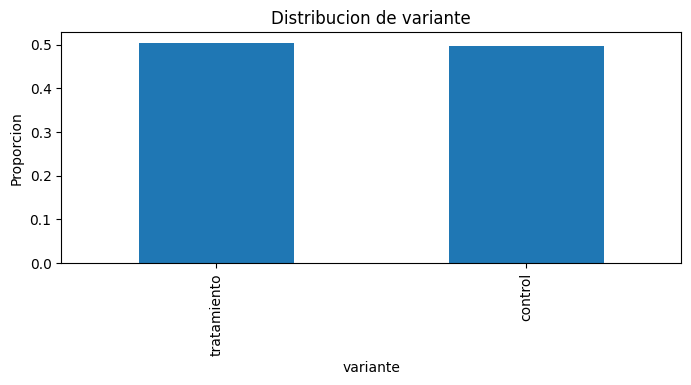

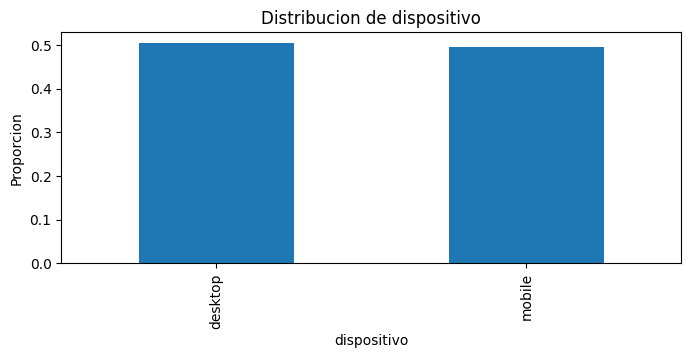

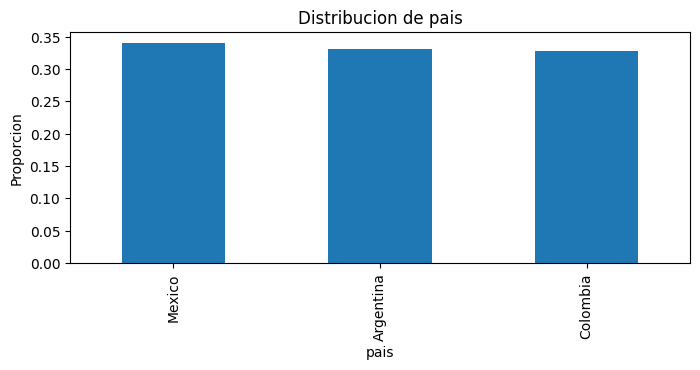

In [ ]:
#Conocer la poblacion (columnas categoricas)
print("----------------------------------------------------------------------------------------------")
print("VARIABLES CATEGORICAS")
print("----------------------------------------------------------------------------------------------")
for col in variables_cat:
    proporciones= expAB[col].value_counts(normalize= True)
    plt.figure(figsize= (8,3))
    proporciones.plot(kind= "bar")
    plt.title(f'Distribucion de {col}')
    plt.ylabel("Proporcion")
    plt.xlabel(col)
    plt.show

----------------------------------------------------------------------------------------------
VARIABLES NUMERICAS
----------------------------------------------------------------------------------------------


<function matplotlib.pyplot.show(close=None, block=None)>

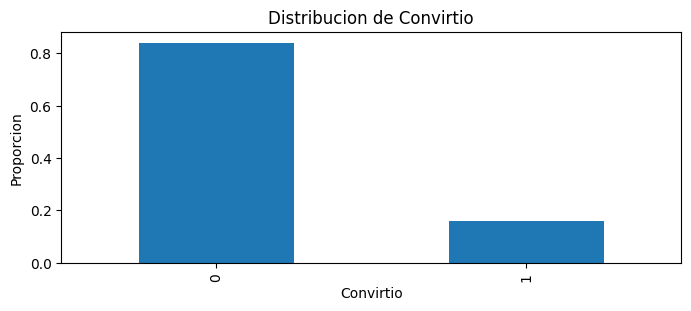

In [ ]:
#Conocer la poblacion (columnas numericas)
print("----------------------------------------------------------------------------------------------")
print("VARIABLES NUMERICAS")
print("----------------------------------------------------------------------------------------------")
proporciones_convirtio= expAB['convirtio'].value_counts(normalize= True).sort_index()
plt.figure(figsize= (8,3))
proporciones_convirtio.plot(kind= "bar")
plt.title('Distribucion de Convirtio')
plt.ylabel("Proporcion")
plt.xlabel('Convirtio')
plt.show

In [ ]:
#Definimos el tamño de la muestra
muestra= expAB.sample(n=1500, random_state= 81)

#Validacion de proporciones similares a la poblacion
for col in variables_cat:
    print(f'Columna {col}')
    print(muestra[col].value_counts(normalize=True))
    print()

Columna variante
control        0.508667
tratamiento    0.491333
Name: variante, dtype: float64

Columna dispositivo
desktop    0.514667
mobile     0.485333
Name: dispositivo, dtype: float64

Columna pais
Argentina    0.348000
Mexico       0.340667
Colombia     0.311333
Name: pais, dtype: float64



In [ ]:
proporciones_convirtio= muestra['convirtio'].value_counts(normalize=True).sort_index()
print(proporciones_convirtio)

0    0.836
1    0.164
Name: convirtio, dtype: float64


In [ ]:
#Creacion de grupos de experimento
muestra_a= muestra.sample(frac=0.5, random_state= 4)
muestra_b= muestra.drop(muestra_a.index)

#Validar que los grupos sean comparables
print("Grupo control")
print(muestra_a['variante'].value_counts(normalize=True))
print("Grupo prueba")
print(muestra_b['variante'].value_counts(normalize=True))

Grupo control
control        0.514667
tratamiento    0.485333
Name: variante, dtype: float64
Grupo prueba
control        0.502667
tratamiento    0.497333
Name: variante, dtype: float64


**Observaciones**

Como vamos a evaluar porcentajes de conversion, la prueba adecuada es la z-test.


In [ ]:
conversiones= expAB.groupby('variante')['convirtio'].sum()
totales= expAB.groupby('variante')['convirtio'].count()
print("Conversiones: ")
print(conversiones)
print("\nTotales: ")
print(totales)

Conversiones: 
variante
control        779
tratamiento    820
Name: convirtio, dtype: int64

Totales: 
variante
control        4965
tratamiento    5035
Name: convirtio, dtype: int64


In [ ]:
#Pasar los valores a formato lista
exitos= [conversiones['tratamiento'], conversiones['control']]
observaciones= [totales['tratamiento'], totales['control']]

#Aplicar prueba y visualizar resultados
z_stat, p_value= proportions_ztest(exitos, observaciones)
print(f'Estadistico z= {z_stat:.4f}')
print(f'Valor p= {p_value:.4f}')

if p_value < 0.05:
    print("\nRechazamos hipotesis nula: hay evidencia de una diferencia.")
else:
    print("\nNo rechazamos hipotesis nula: no hay evidencia suficiente de una diferencia.")


Estadistico z= 0.8133
Valor p= 0.4161

No rechazamos hipotesis nula: no hay evidencia suficiente de una diferencia.


**Resultado**
La tasa de conversión fue de 15.69% en control y 16.29% en tratamiento, una diferencia de +0.6 pp (~+3.8% relativo). Con z = -0.81 y p = 0.42, la diferencia no es estadísticamente significativa: no se detectó un efecto del cambio con esta muestra.

**Recomendacion**
No hay evidencia suficiente para implementar el cambio con base en la conversión. Antes de decidir, hay que completar las validaciones (SRM, balance por dispositivo y país) y calcula el intervalo de confianza.

---

## 🔹 Paso 6: Comunicar los resultados (Dashboard en BI)

🎯 **Objetivo**:  
Crear un dashboard que muestre de manera clara y visual los resultados del análisis de ventas, costos, marketing y conversión.

Se usarán los CSVs limpios del Paso 1:

- `orders_clean.csv`  
- `catalog_clean.csv`  
- `marketing_clean.csv`

---

1️⃣ Preparación de los datos
1. Cargar los CSVs en Power BI o Tableau.
2. Revisar relaciones:
   - `orders.nombre_producto` → `catalog.nombre_producto`
   - `orders.fecha_pedido` → tabla de fechas (crear calendario para análisis temporal)
   - `orders.fecha_pedido` → `dim_fecha.date`
3. Crear columnas calculadas necesarias
4. Crear tabla de fechas para poder calcular comparaciones YTD, YoY o períodos anteriores (`Previous Year`, `Previous Month`).

---

2️⃣ Dashboard 1: Overview Ejecutivo
**KPIs principales a mostrar:**
- Revenue total
- Profit total
- Gasto total en marketing
- Ticket promedio
- Cantidad promedio de productos por orden

**Visualizaciones sugeridas:**
- Tarjetas KPI para revenue, profit y gasto marketing
- Gráfico de líneas: evolución mensual de revenue o profit
- Gráfico de líneas YTD
- Gráfico de barras: revenue y profit por producto o categoría

---

 3️⃣ Dashboard 2: Detalle / Drill-through  
**Objetivo:** Permitir explorar los datos desde el KPI general hasta cada orden o producto.

**Visualizaciones sugeridas:**
- Tabla detallada de órdenes con:
  - producto, cantidad, revenue, cost, profit
  - color condicional (profit negativo en rojo, positivo en verde)
- Gráfico de barras por producto con medida `cantidad vendida`
- Drill-through: seleccionar un producto y ver todos los pedidos relacionados
- Filtros por fecha, categoría de producto, etc

---

## 🚀 Entrega Final

Comparte el acceso a tu Dashboard para revisión.   
Puedes entregar el Dashboard utilizando **Power BI o Tableau**.

Incluye **uno de los siguientes**:

- 🔗 Link público del dashboard publicado en **Power BI Service o Tableau Public / Tableau Cloud**
- 🔗 Link de **Google Drive o OneDrive** con el archivo del proyecto (`.pbix`) y los 3 csvs limpios.


### 📎 Enlace del Dashboard

In [ ]:
# link de one drive / google drive
https://drive.google.com/drive/folders/1E5EVXu0k_jp4xbuf-POVjH0_e9_vHev5?usp=sharing